# Análisis de complejidad y geometría topológica

Calcula métricas por estación, contaminante, año y estación climática. Requiere una exportación de `metadata_table` con las columnas `Date Local`, `Station ID`, `Land Use`, `season`, `Pollutant` y `Arithmetic Mean`.

In [1]:
%pip install antropy nolds scipy seaborn requests

from pathlib import Path
import io
import warnings
import zipfile

import antropy
import matplotlib.pyplot as plt
import nolds
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy.stats import kurtosis, skew

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
OUTPUT_DIR = Path("outputs_complexity")
OUTPUT_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("table_csv")
DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "metadata_table.csv"
MIN_OBSERVATIONS = 20
MIN_CORRELATION_OBSERVATIONS = 50
POLLUTANT_ORDER = ["PM Coarse", "PM10", "PM2.5 FRM/FEM", "PM2.5 non-FRM/FEM"]
LAND_USE_ORDER = ["Rural", "Urban", "Military"]
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Isabella Arrieta G\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Carga y validación de datos

## Preparación integrada desde `entropy.ipynb`

Si `metadata_table.csv` no existe, esta celda reproduce la preparación necesaria: descarga, limpieza, clasificación de estaciones, seasons y construcción de `metadata_table`.

In [2]:
if not DATA_PATH.exists() and "metadata_table" not in globals():
    def leer_zip_aqs(url):
        print(f"Leyendo datos desde: {url}")
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:
            csv_file_name = next(
                (
                    name for name in zip_file.namelist()
                    if name.lower().endswith(".csv") and not name.startswith("__")
                ),
                None,
            )
            if csv_file_name is None:
                raise ValueError(f"No se encontró CSV en {url}")
            with zip_file.open(csv_file_name) as csv_file:
                return pd.read_csv(csv_file, low_memory=False)

    stations = leer_zip_aqs("https://aqs.epa.gov/aqsweb/airdata/aqs_sites.zip")
    colstodrop = [
        "State Code", "County Code", "Site Num", "Parameter Code", "POC",
        "Datum", "Parameter Name", "Pollutant Standard", "Units of Measure",
        "Event Type", "Observation Count", "Observation Percent", "1st Max Value",
        "1st Max Hour", "AQI", "Method Code", "Method Name", "Local Site Name",
        "Address", "State Name", "County Name", "City Name", "CBSA Name",
        "Date of Last Change",
    ]

    pollutant_codes = {
        "PM2.5 FRM/FEM": "88101",
        "PM2.5 non-FRM/FEM": "88502",
        "PM10": "81102",
        "PM Coarse": "86101",
    }
    yearly_data = {
        pollutant: [
            leer_zip_aqs(
                f"https://aqs.epa.gov/aqsweb/airdata/daily_{code}_{year}.zip"
            )
            for year in [2023, 2024, 2025]
        ]
        for pollutant, code in pollutant_codes.items()
    }

    stations = stations.drop(
        columns=[
            "Met Site State Code", "Met Site County Code", "Met Site Site Number",
            "Met Site Distance", "Met Site Direction", "GMT Offset", "Owning Agency",
            "Local Site Name", "Address", "Zip Code", "Tribe Name",
        ],
        errors="ignore",
    )
    stations = stations[stations["Site Closed Date"].isna()].copy()
    land_use_map = {
        "RESIDENTIAL": "Rural",
        "INDUSTRIAL": "Rural",
        "DESERT": "Rural",
        "FOREST": "Rural",
        "COMMERCIAL": "Urban",
        "MILITARY RESERVATION": "Military",
    }
    valid_location_settings = ["RURAL", "SUBURBAN", "URBAN AND CENTER CITY"]
    stations["_land_use_upper"] = stations["Land Use"].str.upper()
    stations_filtered = stations[
        stations["_land_use_upper"].isin(land_use_map)
        & stations["Location Setting"].str.upper().isin(valid_location_settings)
    ].copy()
    stations_filtered = stations_filtered.sort_values(
        ["_land_use_upper", "Latitude", "Longitude"]
    ).reset_index(drop=True)
    stations_filtered["_prefix"] = stations_filtered["_land_use_upper"].map(land_use_map)
    stations_filtered["_rank"] = stations_filtered.groupby("_land_use_upper").cumcount() + 1
    stations_filtered["Station ID"] = (
        stations_filtered["_prefix"] + stations_filtered["_rank"].astype(str)
    )
    station_dataset = stations_filtered[
        ["Station ID", "Land Use", "Location Setting", "Latitude", "Longitude"]
    ].copy()
    station_dataset["Land Use"] = station_dataset["Land Use"].str.upper().map(land_use_map)

    def get_met_season(month):
        if month in [12, 1, 2]:
            return "Winter"
        if month in [3, 4, 5]:
            return "Spring"
        if month in [6, 7, 8]:
            return "Summer"
        return "Fall"

    total_days = 365 + 366 + 365
    threshold = 0.75 * total_days
    consolidated_dfs = {}
    for pollutant, frames in yearly_data.items():
        cleaned_frames = [frame.drop(columns=colstodrop, errors="ignore") for frame in frames if frame is not None]
        if not cleaned_frames:
            continue
        frame = pd.concat(cleaned_frames, ignore_index=True)
        frame["Date Local"] = pd.to_datetime(frame["Date Local"], format="mixed", errors="coerce")
        observation_count = frame.groupby(["Latitude", "Longitude"]).size()
        valid_sites = set(observation_count[observation_count >= threshold].index)
        frame = frame[frame.set_index(["Latitude", "Longitude"]).index.isin(valid_sites)].copy()
        frame["season"] = frame["Date Local"].dt.month.map(get_met_season)
        consolidated_dfs[pollutant] = frame

    metadata_frames = []
    metadata_columns = ["Date Local", "Latitude", "Longitude", "Arithmetic Mean", "season"]
    for pollutant, frame in consolidated_dfs.items():
        current = frame[metadata_columns].copy()
        current["Pollutant"] = pollutant
        metadata_frames.append(current)
    if not metadata_frames:
        raise ValueError("No se pudieron cargar datasets de contaminantes.")
    metadata_table = pd.concat(metadata_frames, ignore_index=True).merge(
        station_dataset,
        on=["Latitude", "Longitude"],
        how="inner",
    )
    metadata_table = metadata_table[
        [
            "Date Local", "Station ID", "Land Use", "Location Setting",
            "Latitude", "Longitude", "season", "Pollutant", "Arithmetic Mean",
        ]
    ].sort_values(["Pollutant", "Station ID", "Date Local"]).reset_index(drop=True)
    metadata_table.to_csv(DATA_PATH, index=False)
    print(f"metadata_table construida y exportada: {len(metadata_table):,} filas")

In [3]:
# Carga metadata_table desde el CSV generado por entropy.ipynb o por la preparación integrada.
DATA_PATH = DATA_DIR / "metadata_table.csv"


def load_metadata(path=DATA_PATH):
    if "metadata_table" in globals() and isinstance(metadata_table, pd.DataFrame):
        return metadata_table.copy()
    if not path.exists():
        raise FileNotFoundError(
            f"No existe {path}. Ejecuta la celda de preparación integrada o entropy.ipynb."
        )
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    return pd.read_csv(path)


metadata = load_metadata()
metadata.columns = [str(column).strip() for column in metadata.columns]
required = {
    "Date Local",
    "Station ID",
    "Land Use",
    "season",
    "Pollutant",
    "Arithmetic Mean",
}
missing = required.difference(metadata.columns)
if missing:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing)}")

metadata["Date Local"] = pd.to_datetime(metadata["Date Local"], errors="coerce")
metadata["Arithmetic Mean"] = pd.to_numeric(metadata["Arithmetic Mean"], errors="coerce")
metadata["Year"] = metadata["Date Local"].dt.year
metadata = metadata.dropna(
    subset=["Date Local", "Arithmetic Mean", "Station ID", "Pollutant"]
).copy()
metadata["Land Use"] = metadata["Land Use"].replace(
    {
        "RESIDENTIAL": "Rural",
        "URBAN AND CENTER CITY": "Urban",
        "MILITARY RESERVATION": "Military",
    }
)
metadata = metadata[metadata["Year"].isin([2023, 2024, 2025])].copy()
print(f"Registros válidos: {len(metadata):,}; estaciones: {metadata['Station ID'].nunique():,}")

Registros válidos: 2,889,704; estaciones: 1,021


## Métricas de una serie

In [4]:
def clean_series(values):
    series = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy(dtype=float)
    if len(series) < MIN_OBSERVATIONS or not np.isfinite(series).all() or np.std(series) == 0:
        return None
    return (series - np.mean(series)) / np.std(series)


def safe_metric(function, series, **kwargs):
    try:
        value = function(series, **kwargs)
        return float(value) if np.isfinite(value) else np.nan
    except (ValueError, FloatingPointError, RuntimeError, ZeroDivisionError):
        return np.nan


def statistical_complexity_mpr(series, order=3, delay=1):
    # Complejidad estadistica de Shannon (Martin-Platino-Rosso, Batista et al. 2014): C = Q_J * H.
    # H: entropia de Shannon normalizada de la distribucion de patrones ordinales.
    # Q_J: desequilibrio de Jensen-Shannon respecto a la distribucion uniforme.
    series = np.asarray(series, dtype=float)
    n_vectors = len(series) - (order - 1) * delay
    if n_vectors < 2:
        return np.nan
    embedded = np.array([series[i:i + order * delay:delay] for i in range(n_vectors)])
    ranks = np.argsort(np.argsort(embedded, axis=1, kind="stable"), axis=1, kind="stable")
    _, counts = np.unique(ranks, axis=0, return_counts=True)
    n_states = 1.0
    for i in range(2, order + 1):
        n_states *= i
    full = np.zeros(int(n_states))
    full[:len(counts)] = counts / counts.sum()

    def shannon(q):
        q = q[q > 0]
        return float(-np.sum(q * np.log(q)))

    s_p = shannon(full)
    h = s_p / np.log(n_states)
    s_mix = shannon(0.5 * (full + 1.0 / n_states))
    jsd = s_mix - 0.5 * s_p - 0.5 * np.log(n_states)
    q0 = -2.0 / (((n_states + 1.0) / n_states) * np.log(n_states + 1.0) - 2.0 * np.log(2.0 * n_states) + np.log(n_states))
    return float(max(0.0, q0 * jsd * h))


def calculate_metrics(values):
    series = clean_series(values)
    if series is None:
        return None
    try:
        hjorth_mobility, hjorth_complexity = antropy.hjorth_params(series)
    except (ValueError, FloatingPointError, RuntimeError, ZeroDivisionError):
        hjorth_mobility = hjorth_complexity = np.nan
    result = {
        "n_observations": len(series),
        "sample_entropy": safe_metric(nolds.sampen, series, emb_dim=2),
        "permutation_entropy": safe_metric(antropy.perm_entropy, series, order=3, normalize=True),
        "svd_entropy": safe_metric(antropy.svd_entropy, series, order=3, normalize=True),
        "statistical_complexity": safe_metric(statistical_complexity_mpr, series, order=3, delay=1),
        "skewness": float(skew(series)),
        "kurtosis": float(kurtosis(series)),
        "hjorth_activity": float(np.var(series)),
        "hjorth_mobility": float(hjorth_mobility),
        "hjorth_complexity": float(hjorth_complexity),
        "higuchi_fractal_dimension": safe_metric(antropy.higuchi_fd, series, kmax=min(10, len(series) // 2)),
        "correlation_dimension": np.nan,
    }
    if len(series) >= MIN_CORRELATION_OBSERVATIONS:
        result["correlation_dimension"] = safe_metric(nolds.corr_dim, series, emb_dim=2)
    return result

In [5]:
group_columns = ["Station ID", "Land Use", "Pollutant", "Year", "season"]
metric_rows = []
for keys, group in metadata.groupby(group_columns, dropna=False, sort=False):
    metrics = calculate_metrics(group["Arithmetic Mean"].to_numpy())
    if metrics is not None:
        metric_rows.append(dict(zip(group_columns, keys), **metrics))

metrics_table = pd.DataFrame(metric_rows)
if metrics_table.empty:
    raise ValueError("No hay grupos con suficientes observaciones y variación para calcular métricas.")
metrics_table.to_csv(OUTPUT_DIR / "metrics_by_station_pollutant_period.csv", index=False)
display(metrics_table.head())
print(f"Grupos analizados: {len(metrics_table):,}")

,Station ID,Land Use,Pollutant,Year,season,n_observations,sample_entropy,permutation_entropy,svd_entropy,statistical_complexity,skewness,kurtosis,hjorth_activity,hjorth_mobility,hjorth_complexity,higuchi_fractal_dimension,correlation_dimension
0,Rural1023,Rural,PM Coarse,2023,Winter,119,1.834062,0.991253,0.964364,0.008463,1.197557,1.296465,1.0,1.047063,1.517049,1.913630,1.260297
1,Rural1023,Rural,PM Coarse,2023,Spring,123,1.506543,0.965683,0.931011,0.035173,0.853659,0.177317,1.0,0.877257,1.719669,1.890449,1.187036
2,Rural1023,Rural,PM Coarse,2023,Summer,121,1.313067,0.995824,0.934652,0.004137,5.510425,37.987238,1.0,0.927232,1.535177,1.893458,1.637660
3,Rural1023,Rural,PM Coarse,2023,Fall,120,1.902108,0.969192,0.928780,0.028798,1.014986,1.401479,1.0,0.896468,1.644465,1.810202,1.336850
4,Rural1023,Rural,PM Coarse,2024,Winter,121,1.456912,0.972988,0.952374,0.025046,1.503049,3.130018,1.0,0.984147,1.585052,1.893844,1.468959


Grupos analizados: 16,611


## Pivots y mapas de calor

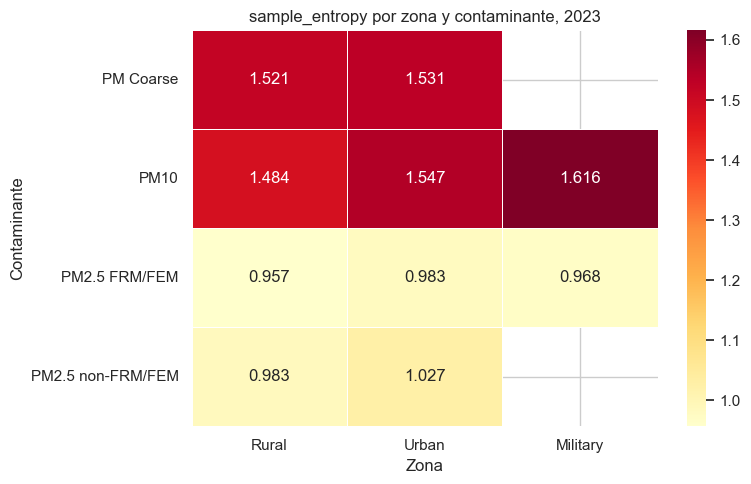

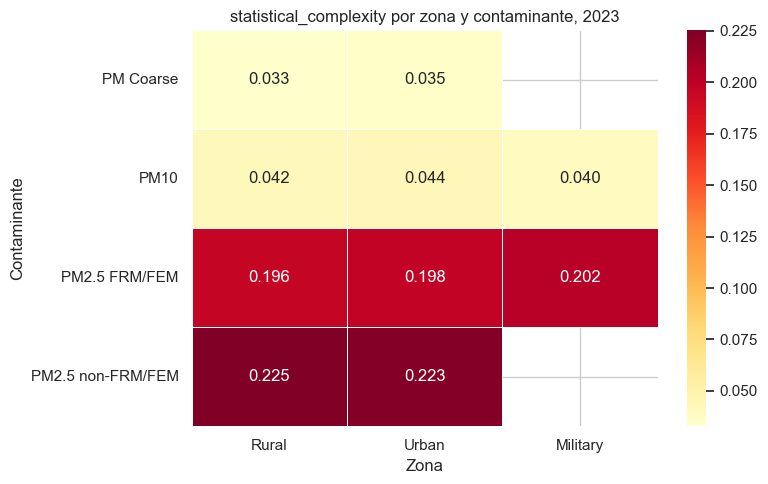

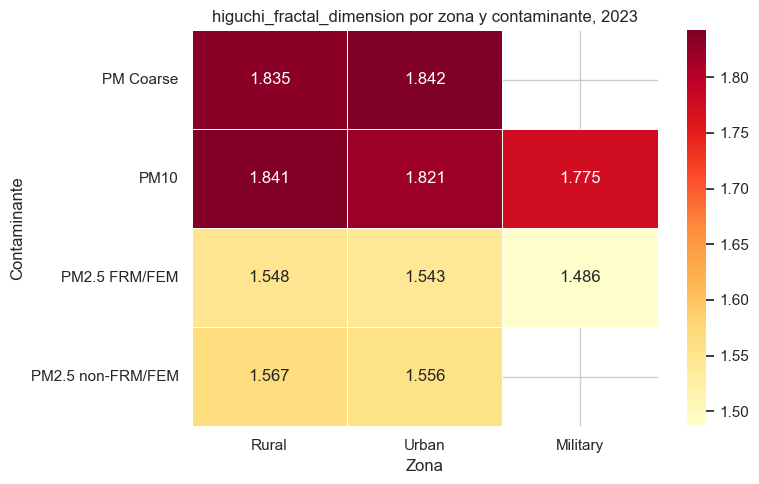

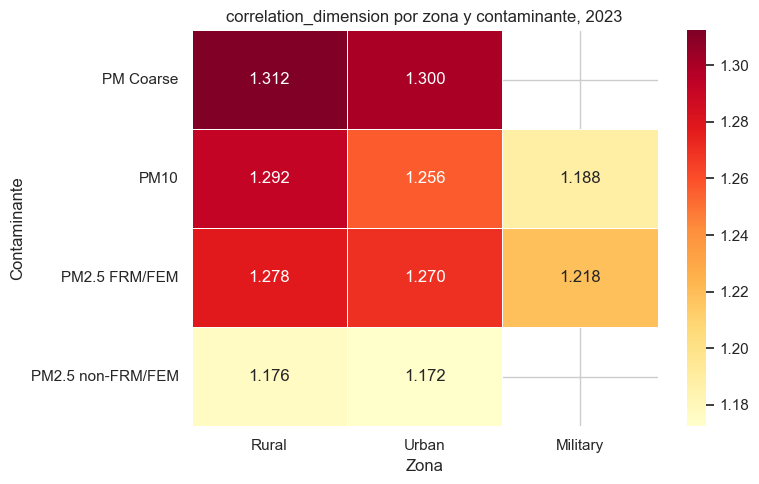

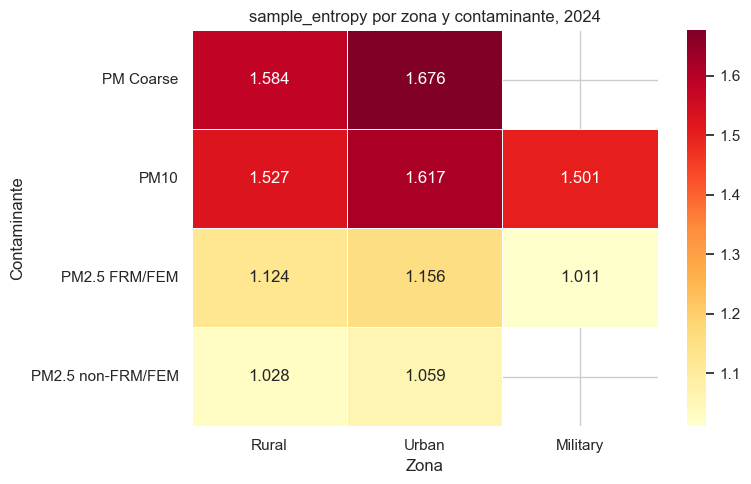

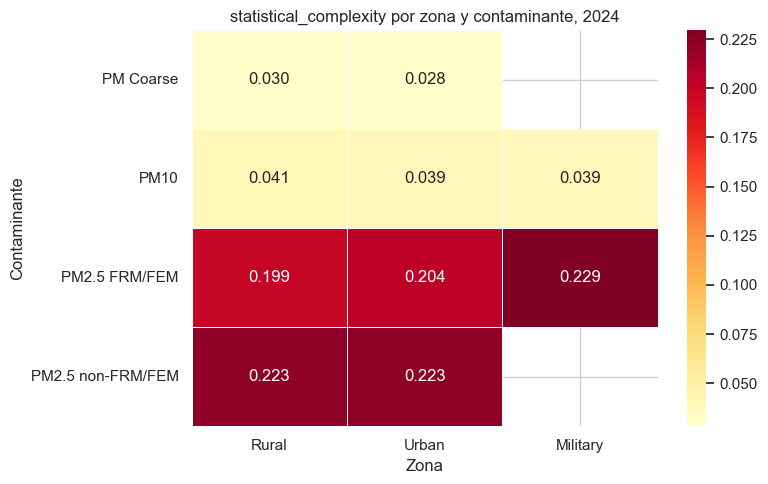

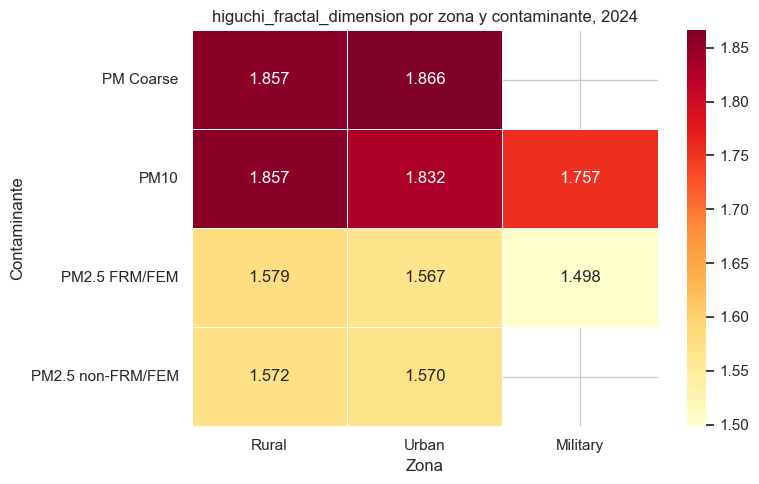

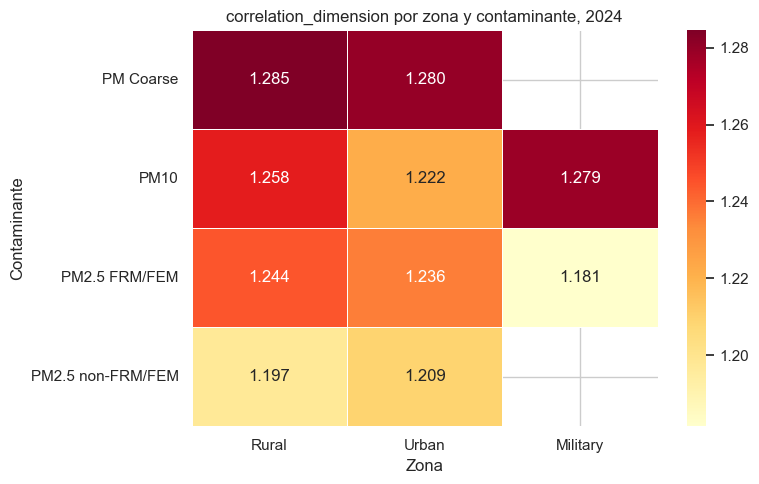

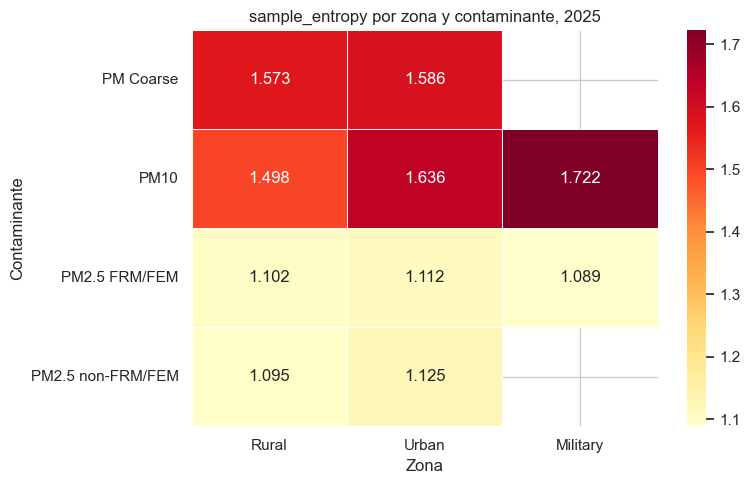

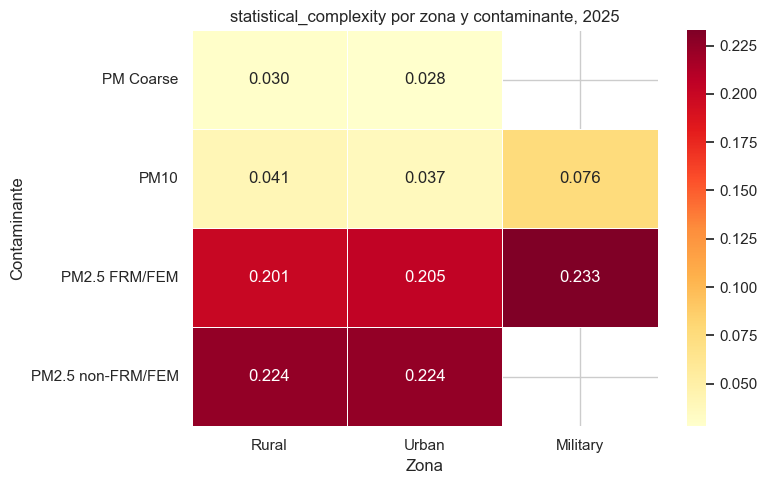

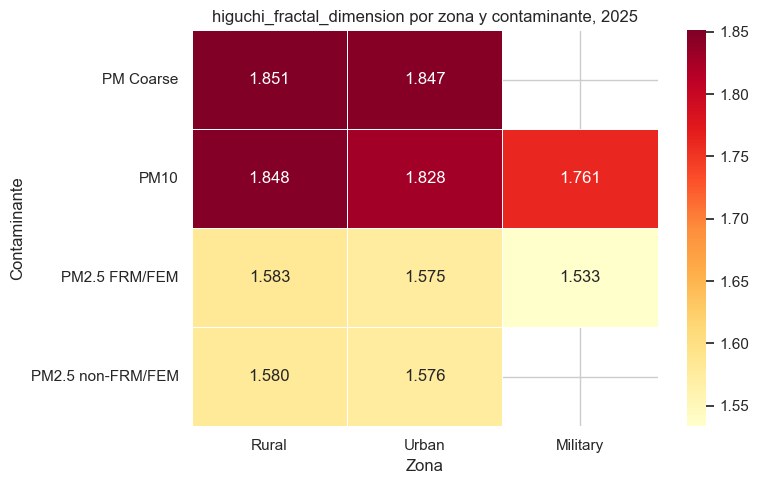

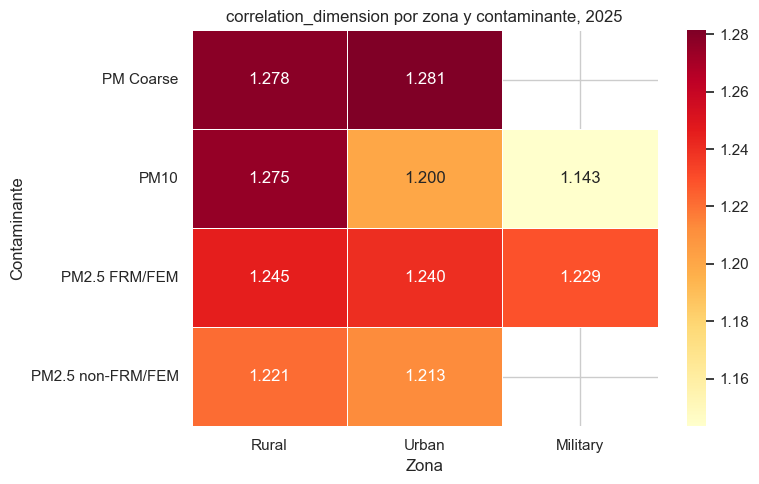

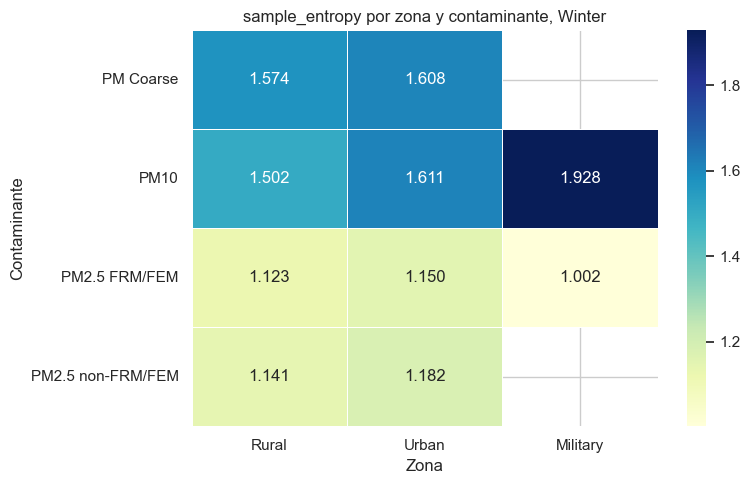

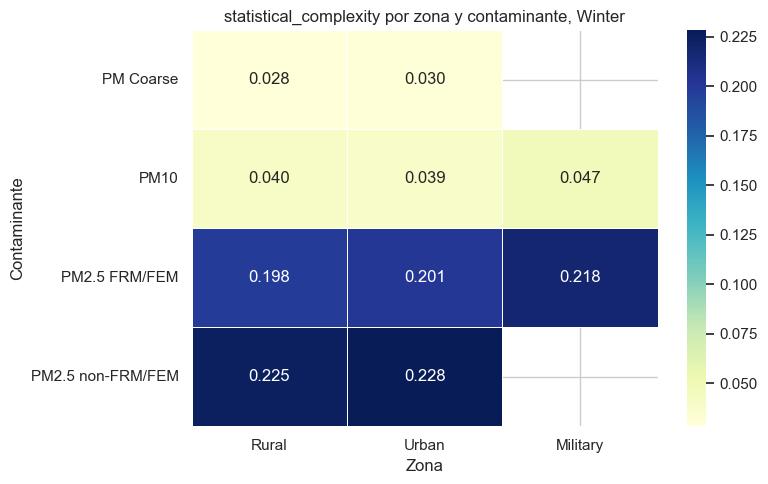

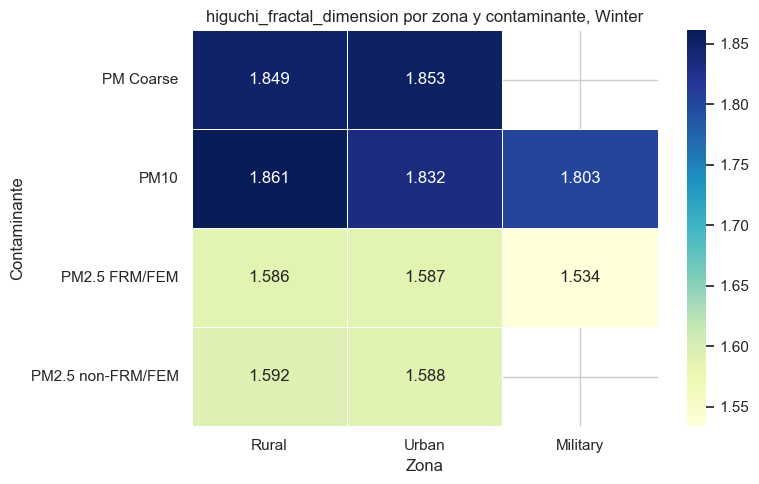

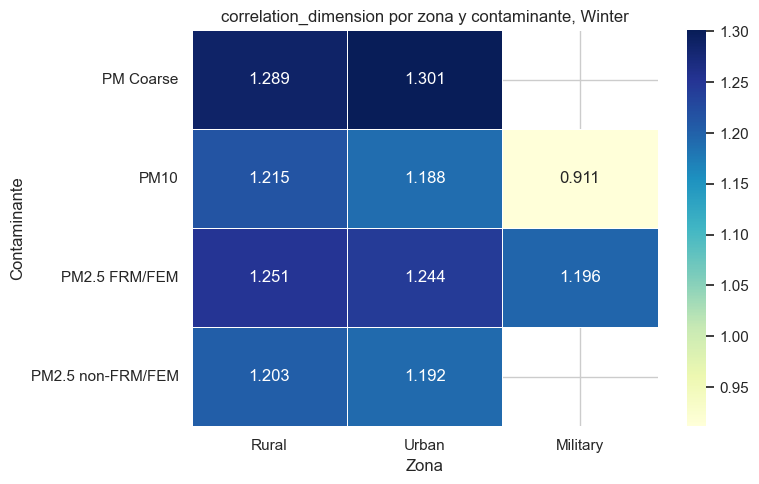

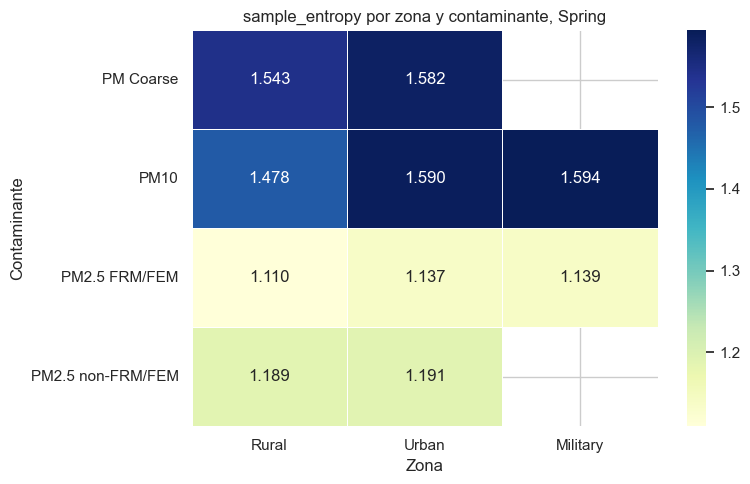

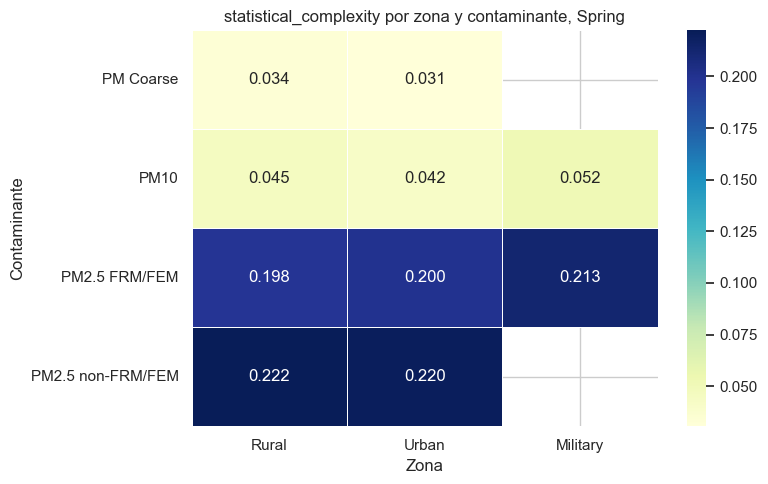

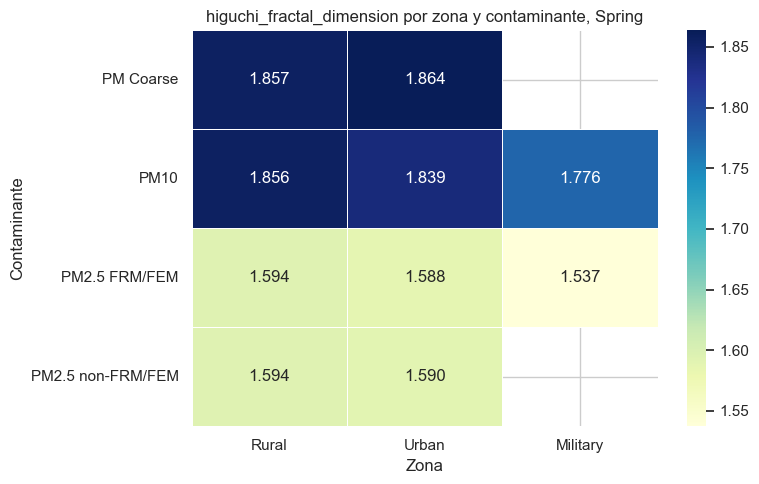

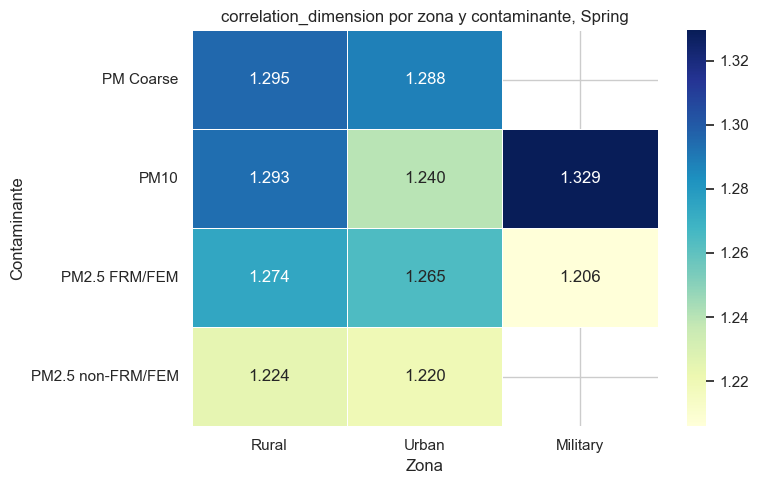

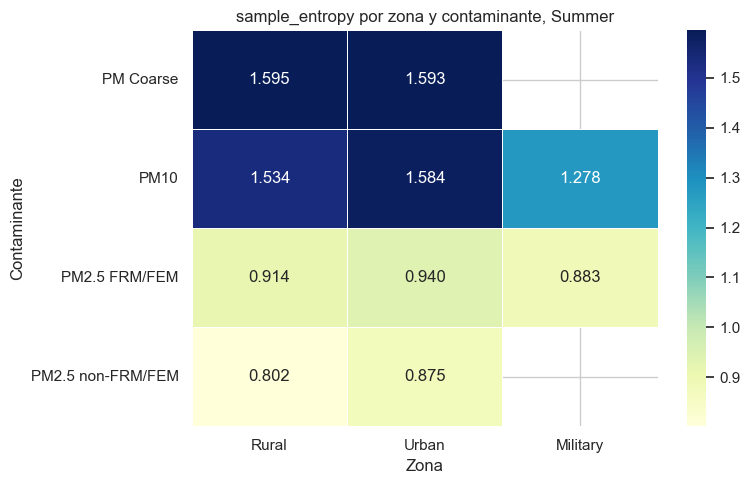

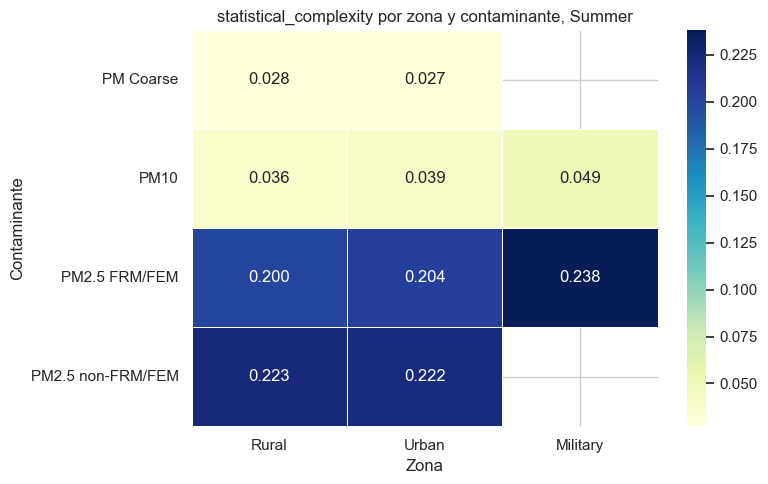

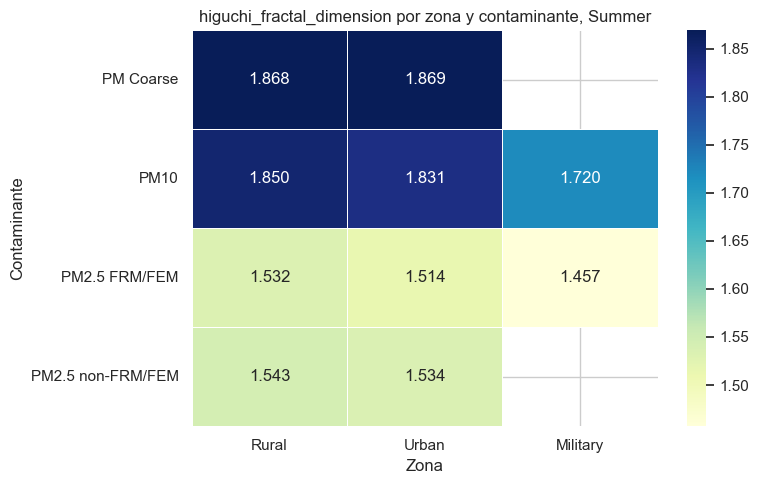

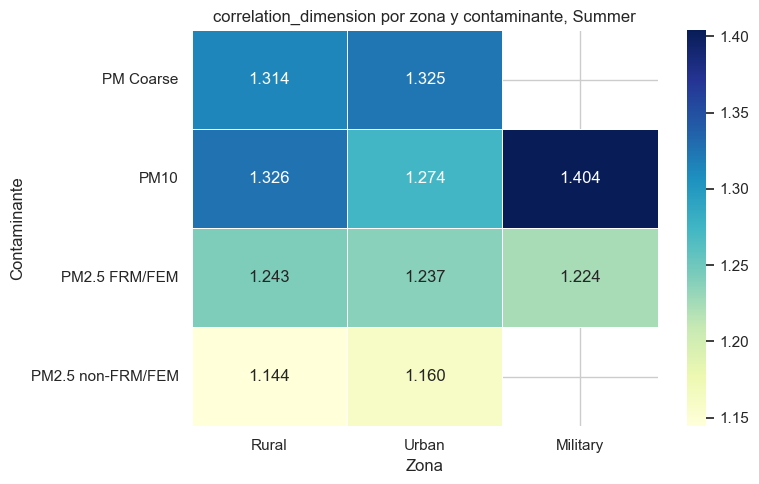

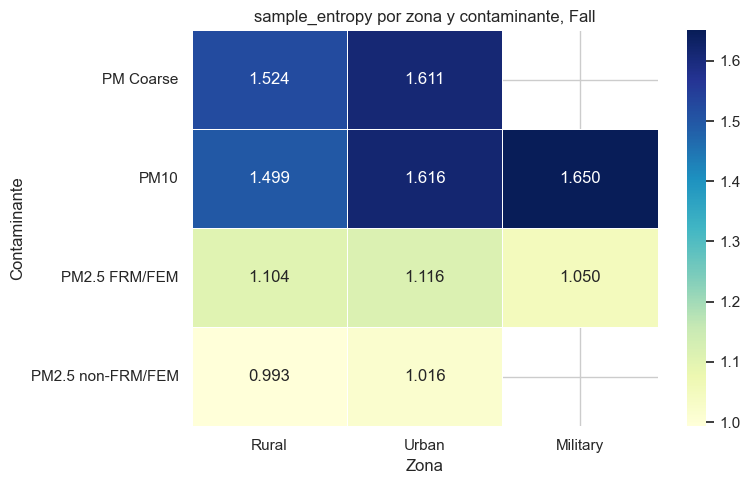

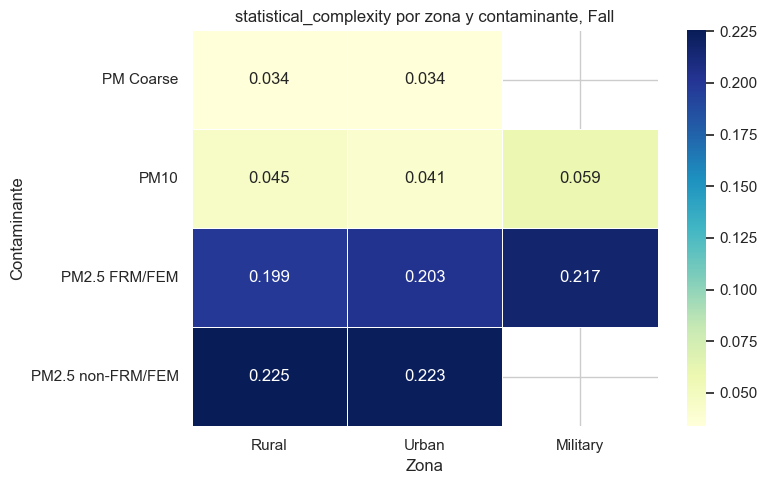

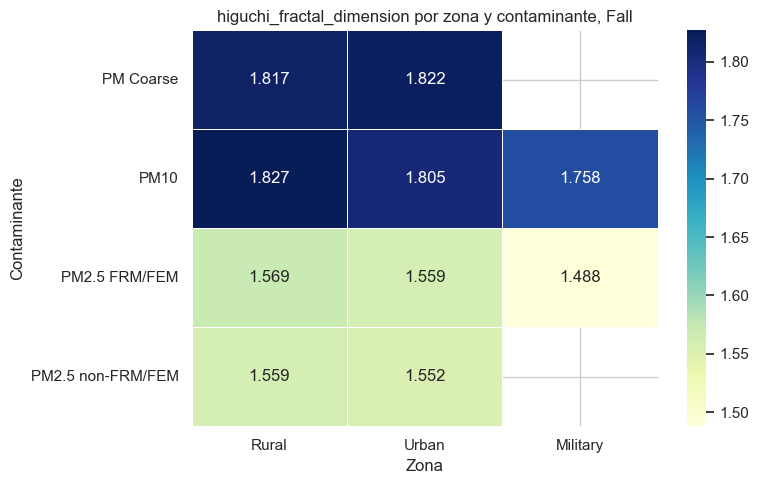

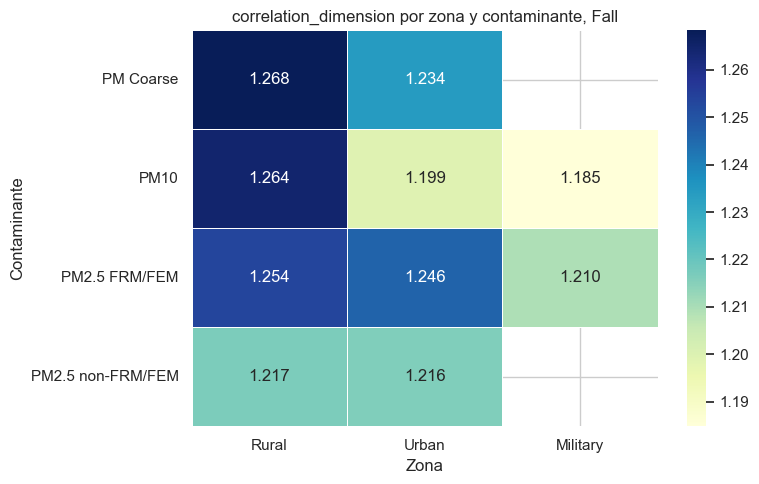

In [6]:
plot_metrics = [
    "sample_entropy",
    "statistical_complexity",
    "higuchi_fractal_dimension",
    "correlation_dimension",
]
pivot_tables = {}


def make_pivot(frame, metric, filters):
    mask = np.logical_and.reduce(
        [frame[column].eq(value) for column, value in filters.items()]
    )
    selected = frame.loc[mask]
    return (
        selected.pivot_table(
            index="Pollutant",
            columns="Land Use",
            values=metric,
            aggfunc="mean",
        )
        .reindex(index=POLLUTANT_ORDER, columns=LAND_USE_ORDER)
    )


for year in sorted(metrics_table["Year"].dropna().unique()):
    for metric in plot_metrics:
        pivot = make_pivot(metrics_table, metric, {"Year": year})
        pivot_tables[("year", year, metric)] = pivot
        pivot.to_csv(OUTPUT_DIR / f"pivot_{metric}_{int(year)}.csv")
        if pivot.notna().any().any():
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.heatmap(
                pivot,
                annot=True,
                fmt=".3f",
                cmap="YlOrRd",
                linewidths=0.5,
                ax=ax,
            )
            ax.set(
                xlabel="Zona",
                ylabel="Contaminante",
                title=f"{metric} por zona y contaminante, {int(year)}",
            )
            fig.tight_layout()
            fig.savefig(OUTPUT_DIR / f"heatmap_{metric}_{int(year)}.png", dpi=150)
            plt.show()

for season in SEASON_ORDER:
    for metric in plot_metrics:
        pivot = make_pivot(metrics_table, metric, {"season": season})
        pivot_tables[("season", season, metric)] = pivot
        pivot.to_csv(OUTPUT_DIR / f"pivot_{metric}_{season.lower()}.csv")
        if pivot.notna().any().any():
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.heatmap(
                pivot,
                annot=True,
                fmt=".3f",
                cmap="YlGnBu",
                linewidths=0.5,
                ax=ax,
            )
            ax.set(
                xlabel="Zona",
                ylabel="Contaminante",
                title=f"{metric} por zona y contaminante, {season}",
            )
            fig.tight_layout()
            fig.savefig(OUTPUT_DIR / f"heatmap_{metric}_{season.lower()}.png", dpi=150)
            plt.show()

In [7]:
# Una fila por estación y periodo: evita repetir una estación por contaminante.
coordinate_columns = {"Latitude", "Longitude"}
if coordinate_columns.issubset(metadata.columns):
    coordinates = (
        metadata.groupby("Station ID")[list(coordinate_columns)]
        .first()
        .reset_index()
    )
    geo_base = metrics_table.merge(coordinates, on="Station ID", how="left")
    geo_base = geo_base.dropna(subset=["Latitude", "Longitude"])
    geo_year = (
        geo_base.groupby(
            ["Station ID", "Land Use", "Year", "Latitude", "Longitude"],
            as_index=False,
        )[plot_metrics]
        .mean()
    )
    geo_year_season = (
        geo_base.groupby(
            ["Station ID", "Land Use", "Year", "season", "Latitude", "Longitude"],
            as_index=False,
        )[plot_metrics]
        .mean()
    )

    def plot_geo(frame, metric, title, output_name):
        frame = frame.dropna(subset=[metric])
        if frame.empty:
            return
        fig, ax = plt.subplots(figsize=(10, 7))
        points = ax.scatter(
            frame["Longitude"],
            frame["Latitude"],
            c=frame[metric],
            s=70,
            cmap="viridis",
            edgecolors="black",
            linewidths=0.3,
        )
        for _, row in frame.iterrows():
            ax.annotate(
                row["Station ID"],
                (row["Longitude"], row["Latitude"]),
                fontsize=5,
                xytext=(2, 2),
                textcoords="offset points",
            )
        fig.colorbar(points, ax=ax, label=metric)
        ax.set(xlabel="Longitude", ylabel="Latitude", title=title)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / output_name, dpi=120)
        plt.close(fig)

    for year in sorted(geo_year["Year"].unique()):
        year_frame = geo_year.query("Year == @year")
        for metric in plot_metrics:
            plot_geo(
                year_frame,
                metric,
                f"{metric} por estación, {int(year)}",
                f"geo_{metric}_{int(year)}.png",
            )

    for year in sorted(geo_year_season["Year"].unique()):
        for season in SEASON_ORDER:
            period_frame = geo_year_season.query(
                "Year == @year and season == @season"
            )
            for metric in plot_metrics:
                plot_geo(
                    period_frame,
                    metric,
                    f"{metric}: {season} {int(year)}",
                    f"geo_{metric}_{int(year)}_{season.lower()}.png",
                )
    print(f"Mapas geoespaciales guardados en {OUTPUT_DIR.resolve()}")
else:
    print("No hay Latitude/Longitude; se omiten los mapas geoespaciales.")

Mapas geoespaciales guardados en C:\Users\Isabella Arrieta G\Codes\ProyectoSemillero-2026\ProyectoSemillero\outputs_complexity


sample_entropy                               permutation_entropy  \
                  count      mean    median       std               count   
Land Use                                                                    
Military             93  1.243185  1.197257  0.526009                  93   
Rural             10905  1.211820  1.207812  0.456706               10992   
Urban              5476  1.244340  1.233302  0.447984                5526   

                                       svd_entropy            ...  kurtosis  \
              mean    median       std       count      mean  ...    median   
Land Use                                                      ...             
Military  0.789736  0.756174  0.136848          93  0.853464  ...  0.879817   
Rural     0.810985  0.783501  0.125141       10992  0.880515  ...  1.919034   
Urban     0.803985  0.769216  0.124645        5526  0.875615  ...  1.541421   

                    higuchi_fractal_dimension                                \
                std                     count      mean    median       std   
Land Use                                                                      
Military   5.758071                        93  1.602548  1.575717  0.174605   
Rural     11.194203                     10992  1.665481  1.632901  0.172539   
Urban      8.758547                      5526  1.647693  1.615039  0.163515   

         correlation_dimension                                
                         count      mean    median       std  
Land Use                                                      
Military                    92  1.206844  1.222238  0.290912  
Rural                    10809  1.255343  1.264296  0.206055  
Urban                     5393  1.239180  1.253554  0.204428  

[3 rows x 32 columns]

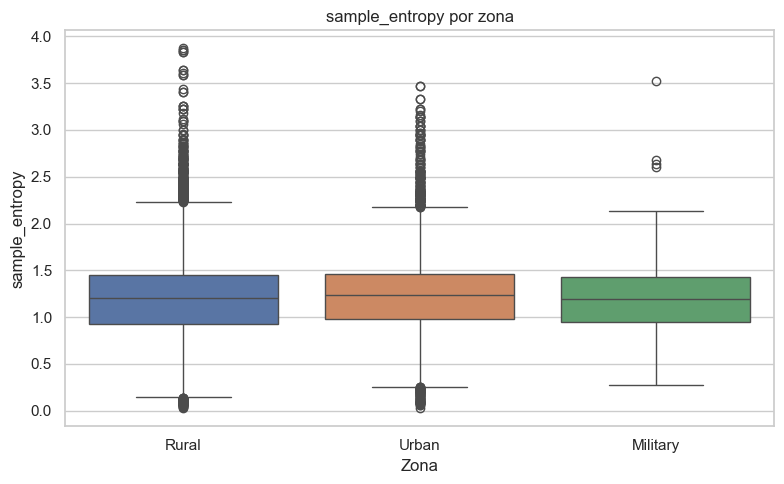

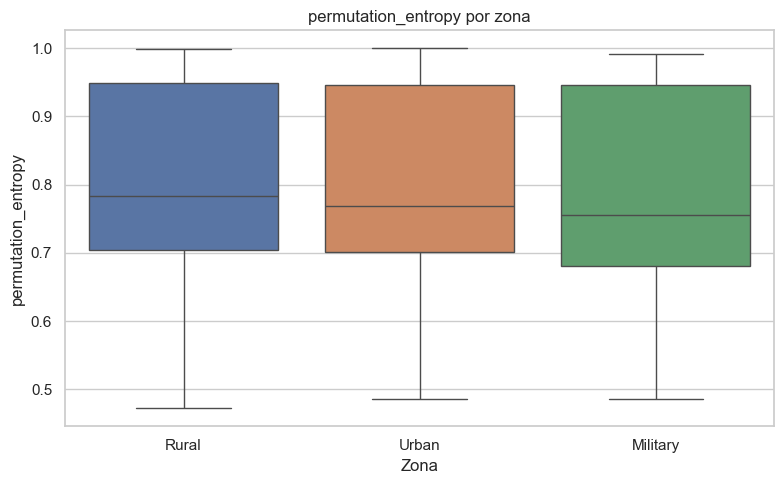

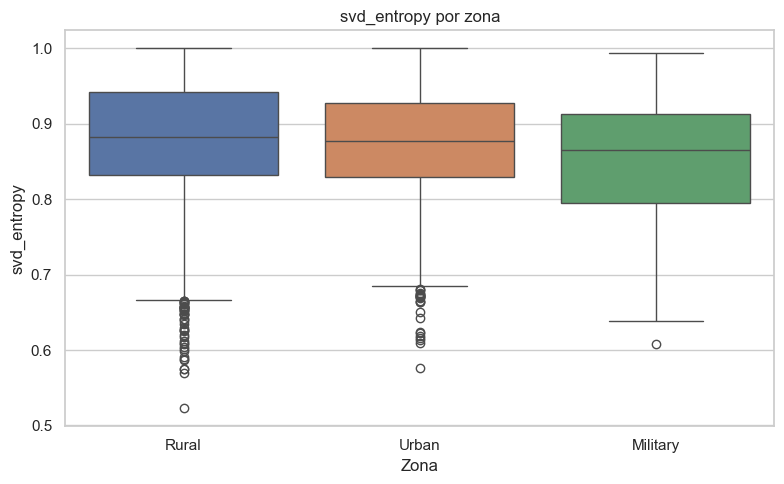

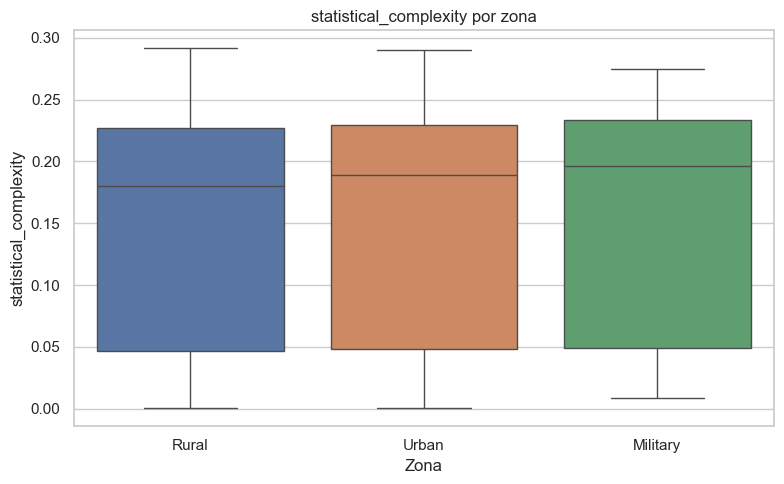

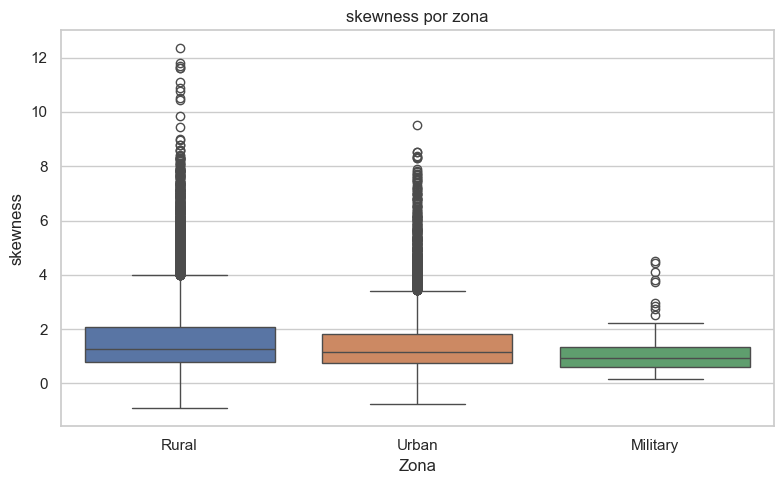

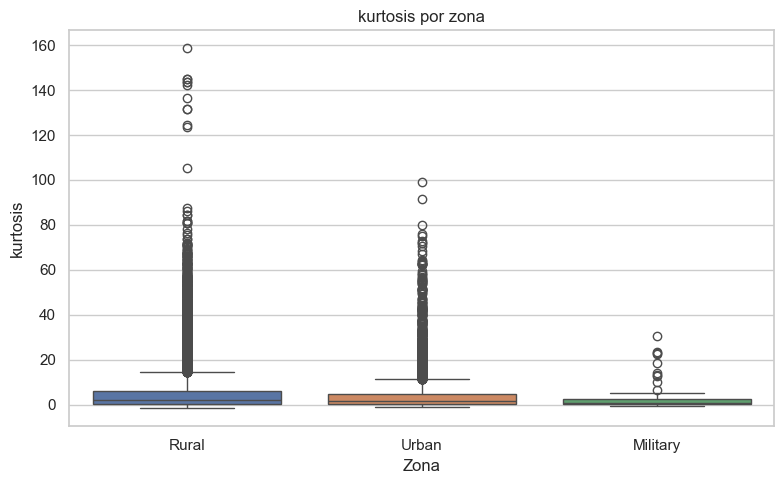

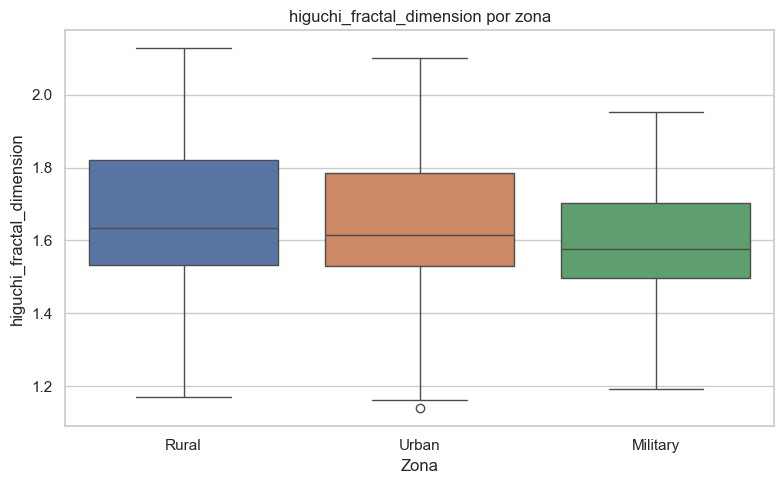

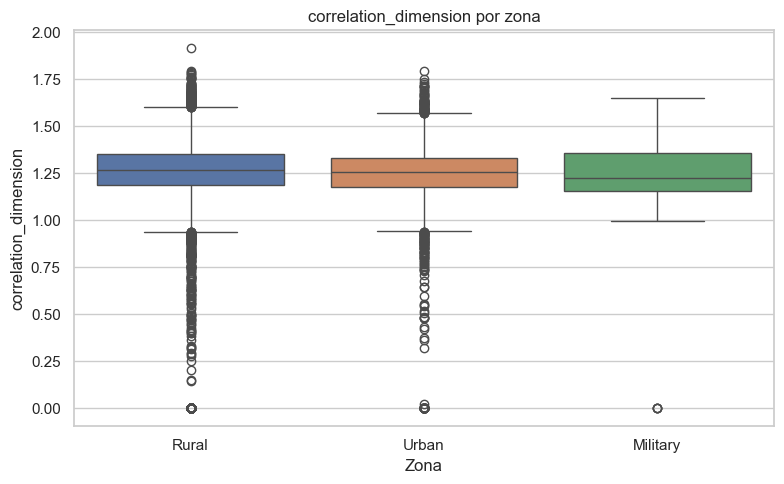

Resultados guardados en: C:\Users\Isabella Arrieta G\Codes\ProyectoSemillero-2026\ProyectoSemillero\outputs_complexity


In [8]:
topology_metrics = [
    "sample_entropy",
    "permutation_entropy",
    "svd_entropy",
    "statistical_complexity",
    "skewness",
    "kurtosis",
    "higuchi_fractal_dimension",
    "correlation_dimension",
]
summary = (
    metrics_table.groupby("Land Use")[topology_metrics]
    .agg(["count", "mean", "median", "std"])
)
summary.to_csv(OUTPUT_DIR / "topology_summary_by_land_use.csv")

display(summary)

for metric in topology_metrics:
    comparison = metrics_table.dropna(subset=[metric])
    if comparison.empty:
        continue
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(
        data=comparison,
        x="Land Use",
        y=metric,
        order=LAND_USE_ORDER,
        hue="Land Use",
        legend=False,
        ax=ax,
    )
    ax.set_title(f"{metric} por zona")
    ax.set_xlabel("Zona")
    ax.set_ylabel(metric)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"topology_{metric}_by_land_use.png", dpi=150)
    plt.show()

print(f"Resultados guardados en: {OUTPUT_DIR.resolve()}")